# Ice Cream Revenue Prediction
**Goal:** predict daily ice cream shop revenue from the day's temperature using Linear Regression.

**Contents**
1. Import libraries
2. Load and explore data
3. Define target and features
4. Train-test split
5. Train the model
6. Evaluate the model
7. Visualize the results
8. Make a prediction
9. Challenges and how I solved them
10. Conclusion

## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score

## 2. Load and explore data
The dataset has two columns: `Temperature` (°C) and `Revenue`. Before modelling I check its size, summary statistics, missing values, and how strongly the two columns are related.

In [2]:
icecream = pd.read_csv('https://github.com/ybifoundation/Dataset/raw/main/Ice%20Cream.csv')
print('Shape:', icecream.shape)
icecream.head()

Shape: (500, 2)


,Temperature,Revenue
0,24.6,535
1,26.1,626
2,27.8,661
3,20.6,488
4,11.6,317


In [3]:
icecream.describe()

,Temperature,Revenue
count,500.000000,500.000000
mean,22.281600,522.058000
std,8.097597,175.410399
min,0.000000,10.000000
25%,17.175000,406.000000
50%,22.400000,530.000000
75%,27.800000,643.000000
max,45.000000,1000.000000


In [4]:
# Check for missing values
icecream.isnull().sum()

Temperature    0
Revenue        0
dtype: int64

In [5]:
# Correlation between temperature and revenue
icecream.corr()

,Temperature,Revenue
Temperature,1.000000,0.989841
Revenue,0.989841,1.000000


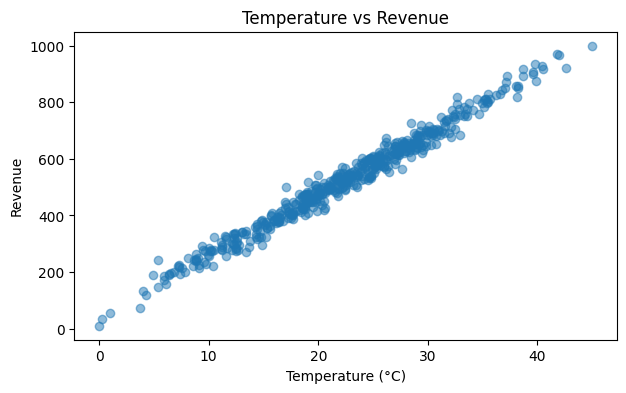

In [6]:
plt.figure(figsize=(7, 4))
plt.scatter(icecream['Temperature'], icecream['Revenue'], alpha=0.5)
plt.xlabel('Temperature (°C)')
plt.ylabel('Revenue')
plt.title('Temperature vs Revenue')
plt.show()

**Observation:** there are no missing values, and the correlation is about 0.99. Revenue rises almost in a straight line with temperature, so Linear Regression is a suitable model.

## 3. Define target (y) and feature (X)

In [7]:
y = icecream['Revenue']          # target
X = icecream[['Temperature']]    # feature (double brackets keep it 2-D)

## 4. Train-test split
70% of the data is used for training and 30% for testing. `random_state` keeps the split the same every run.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=2529)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((350, 1), (150, 1), (350,), (150,))

## 5. Train the model

In [9]:
model = LinearRegression()
model.fit(X_train, y_train)
print('Intercept:', model.intercept_)
print('Coefficient:', model.coef_[0])

Intercept: 42.444772590839705
Coefficient: 21.545871471833944


**Meaning:** each 1°C rise in temperature adds about 21.5 to revenue, and the base revenue at 0°C is about 42.

## 6. Evaluate the model

In [10]:
y_pred = model.predict(X_test)

print('MAE  :', mean_absolute_error(y_test, y_pred))
print('MAPE :', mean_absolute_percentage_error(y_test, y_pred))
print('MSE  :', mean_squared_error(y_test, y_pred))
print('R2   :', r2_score(y_test, y_pred))

MAE  : 19.138687444270737
MAPE : 0.042214848219420134
MSE  : 583.7362763558341
R2   : 0.9803512819448449


**Interpretation:** the model's predictions are off by about 19 on average (MAE), roughly 4% (MAPE). R² of about 0.98 means temperature explains about 98% of the variation in revenue on unseen test data.

## 7. Visualize the results

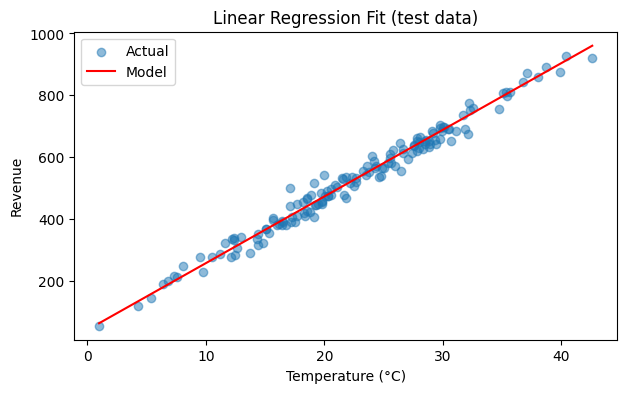

In [11]:
# Fitted line over the test data
X_sorted = X_test.sort_values('Temperature')
plt.figure(figsize=(7, 4))
plt.scatter(X_test, y_test, alpha=0.5, label='Actual')
plt.plot(X_sorted, model.predict(X_sorted), color='red', label='Model')
plt.xlabel('Temperature (°C)')
plt.ylabel('Revenue')
plt.title('Linear Regression Fit (test data)')
plt.legend()
plt.show()

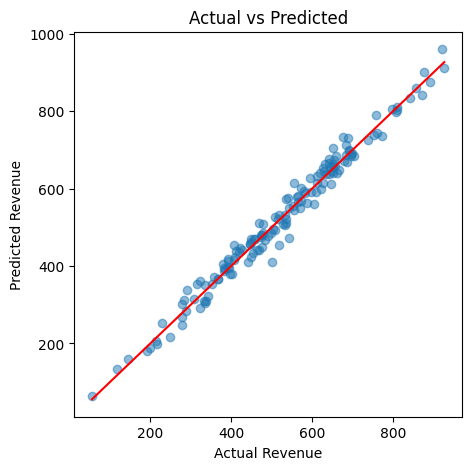

In [12]:
# Actual vs predicted revenue
plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.xlabel('Actual Revenue')
plt.ylabel('Predicted Revenue')
plt.title('Actual vs Predicted')
plt.show()

Points close to the red diagonal mean accurate predictions. Most points sit on it.

## 8. Make a prediction
Estimate revenue for new temperatures.

In [13]:
new_temps = pd.DataFrame({'Temperature': [15, 25, 30, 35]})
new_temps['Predicted Revenue'] = model.predict(new_temps[['Temperature']]).round(2)
new_temps

,Temperature,Predicted Revenue
0,15,365.63
1,25,581.09
2,30,688.82
3,35,796.55


## 9. Challenges and how I solved them
- **Choosing the model:** I first plotted the data and checked the correlation. The near-straight-line pattern showed that simple Linear Regression fits well.
- **Input shape error:** scikit-learn expects a 2-D feature table, so I used `X = icecream[['Temperature']]` with double brackets instead of a single-bracket Series.
- **Checking for overfitting:** I evaluated only on the held-out 30% test set so the scores reflect unseen data.
- **Checking a more complex model:** I tested a degree-2 polynomial regression, and its R² (about 0.980) was no better than the linear model, so I kept the simpler one.

## 10. Conclusion
Temperature is a very strong predictor of ice cream revenue. A simple Linear Regression model reaches an R² of about 0.98 with an average error of about 19 on the test set. A shop owner could use it to estimate demand from the weather forecast and plan stock.

**Limitations and next steps:** the model uses only temperature. Adding features like day of week, holidays, or rainfall could improve it further.